In [1]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data

DATA_PATH = "data/dataset_to_release/dataset"

x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)

print("Données chargées !")
print("Train :", x_train.shape)
print("Test :", x_test.shape)

Données chargées !
Train : (328135, 321)
Test : (109379, 321)


In [2]:
# Nombre total de valeurs manquantes
n_nan = np.isnan(x_train).sum()

# Nombre total de valeurs dans la matrice
n_total = x_train.size

print(f"Valeurs manquantes : {n_nan:,}")
print(f"Pourcentage manquant : {100 * n_nan / n_total:.2f}%")

# Distribution des classes
classes, counts = np.unique(y_train, return_counts=True)

for classe, count in zip(classes, counts):
    print(f"Classe {classe}: {count:,} ({100 * count / len(y_train):.2f}%)")

Valeurs manquantes : 47,175,779
Pourcentage manquant : 44.79%
Classe -1: 299,160 (91.17%)
Classe 1: 28,975 (8.83%)


Colonnes sans NaN : 82
Colonnes avec plus de 50% de NaN : 147
Colonnes avec plus de 90% de NaN : 99
Colonnes entièrement vides : 0


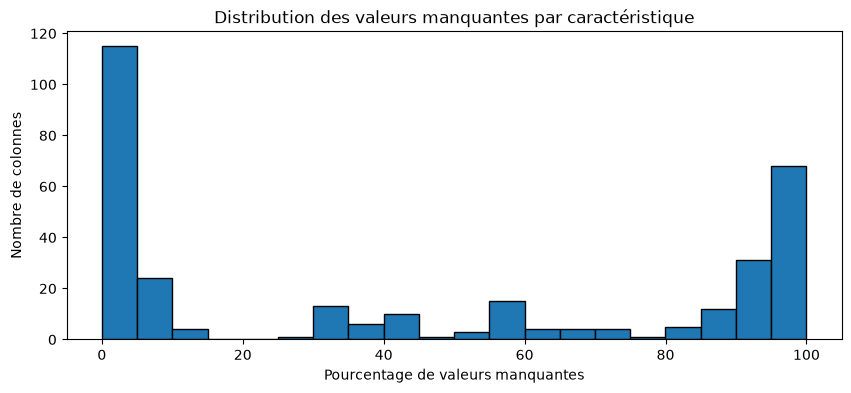

In [3]:
# Pourcentage de valeurs manquantes par colonne
missing_pct = np.mean(np.isnan(x_train), axis=0) * 100

print("Colonnes sans NaN :", np.sum(missing_pct == 0))
print("Colonnes avec plus de 50% de NaN :", np.sum(missing_pct > 50))
print("Colonnes avec plus de 90% de NaN :", np.sum(missing_pct > 90))
print("Colonnes entièrement vides :", np.sum(missing_pct == 100))

# Visualisation
plt.figure(figsize=(10, 4))
plt.hist(missing_pct, bins=20, edgecolor="black")
plt.xlabel("Pourcentage de valeurs manquantes")
plt.ylabel("Nombre de colonnes")
plt.title("Distribution des valeurs manquantes par caractéristique")
plt.show()

In [4]:
# Examiner les 10 premières caractéristiques
for j in range(10):
    col = x_train[:, j]
    valid = col[~np.isnan(col)]

    print(f"Colonne {j}")
    print(f"  NaN : {np.mean(np.isnan(col)) * 100:.1f}%")
    print(f"  Valeurs distinctes : {len(np.unique(valid))}")
    print(f"  Min : {np.min(valid) if len(valid) else 'N/A'}")
    print(f"  Max : {np.max(valid) if len(valid) else 'N/A'}")
    print()

Colonne 0
  NaN : 0.0%
  Valeurs distinctes : 53
  Min : 1.0
  Max : 72.0

Colonne 1
  NaN : 0.0%
  Valeurs distinctes : 12
  Min : 1.0
  Max : 12.0

Colonne 2
  NaN : 0.0%
  Valeurs distinctes : 414
  Min : 1012016.0
  Max : 12312015.0

Colonne 3
  NaN : 0.0%
  Valeurs distinctes : 12
  Min : 1.0
  Max : 12.0

Colonne 4
  NaN : 0.0%
  Valeurs distinctes : 31
  Min : 1.0
  Max : 31.0

Colonne 5
  NaN : 0.0%
  Valeurs distinctes : 2
  Min : 2015.0
  Max : 2016.0

Colonne 6
  NaN : 0.0%
  Valeurs distinctes : 2
  Min : 1100.0
  Max : 1200.0

Colonne 7
  NaN : 0.0%
  Valeurs distinctes : 21780
  Min : 2015000001.0
  Max : 2015023235.0

Colonne 8
  NaN : 0.0%
  Valeurs distinctes : 21780
  Min : 2015000001.0
  Max : 2015023235.0

Colonne 9
  NaN : 42.5%
  Valeurs distinctes : 1
  Min : 1.0
  Max : 1.0



In [5]:
unique_counts = np.array([
    len(np.unique(x_train[~np.isnan(x_train[:, j]), j]))
    for j in range(x_train.shape[1])
])

print("Colonnes constantes :", np.sum(unique_counts <= 1))
print("Colonnes avec 2 valeurs distinctes :", np.sum(unique_counts == 2))
print("Colonnes avec 3 à 10 valeurs :", np.sum((unique_counts >= 3) & (unique_counts <= 10)))
print("Colonnes avec 11 à 50 valeurs :", np.sum((unique_counts >= 11) & (unique_counts <= 50)))
print("Colonnes avec plus de 50 valeurs :", np.sum(unique_counts > 50))

Colonnes constantes : 6
Colonnes avec 2 valeurs distinctes : 14
Colonnes avec 3 à 10 valeurs : 199
Colonnes avec 11 à 50 valeurs : 39
Colonnes avec plus de 50 valeurs : 63


In [6]:
import csv
import os

file_path = os.path.join(DATA_PATH, "x_train.csv")

with open(file_path, newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    column_names = next(reader)

print("Nombre de colonnes dans le CSV :", len(column_names))
print("20 premières colonnes :")
for i, name in enumerate(column_names[:20]):
    print(i, name)

Nombre de colonnes dans le CSV : 322
20 premières colonnes :
0 Id
1 _STATE
2 FMONTH
3 IDATE
4 IMONTH
5 IDAY
6 IYEAR
7 DISPCODE
8 SEQNO
9 _PSU
10 CTELENUM
11 PVTRESD1
12 COLGHOUS
13 STATERES
14 CELLFON3
15 LADULT
16 NUMADULT
17 NUMMEN
18 NUMWOMEN
19 CTELNUM1


In [7]:
# Retirer la colonne Id
feature_names = column_names[1:]

# Afficher toutes les caractéristiques
for i, name in enumerate(feature_names):
    print(f"{i:3d}: {name}")

  0: _STATE
  1: FMONTH
  2: IDATE
  3: IMONTH
  4: IDAY
  5: IYEAR
  6: DISPCODE
  7: SEQNO
  8: _PSU
  9: CTELENUM
 10: PVTRESD1
 11: COLGHOUS
 12: STATERES
 13: CELLFON3
 14: LADULT
 15: NUMADULT
 16: NUMMEN
 17: NUMWOMEN
 18: CTELNUM1
 19: CELLFON2
 20: CADULT
 21: PVTRESD2
 22: CCLGHOUS
 23: CSTATE
 24: LANDLINE
 25: HHADULT
 26: GENHLTH
 27: PHYSHLTH
 28: MENTHLTH
 29: POORHLTH
 30: HLTHPLN1
 31: PERSDOC2
 32: MEDCOST
 33: CHECKUP1
 34: BPHIGH4
 35: BPMEDS
 36: BLOODCHO
 37: CHOLCHK
 38: TOLDHI2
 39: CVDSTRK3
 40: ASTHMA3
 41: ASTHNOW
 42: CHCSCNCR
 43: CHCOCNCR
 44: CHCCOPD1
 45: HAVARTH3
 46: ADDEPEV2
 47: CHCKIDNY
 48: DIABETE3
 49: DIABAGE2
 50: SEX
 51: MARITAL
 52: EDUCA
 53: RENTHOM1
 54: NUMHHOL2
 55: NUMPHON2
 56: CPDEMO1
 57: VETERAN3
 58: EMPLOY1
 59: CHILDREN
 60: INCOME2
 61: INTERNET
 62: WEIGHT2
 63: HEIGHT3
 64: PREGNANT
 65: QLACTLM2
 66: USEEQUIP
 67: BLIND
 68: DECIDE
 69: DIFFWALK
 70: DIFFDRES
 71: DIFFALON
 72: SMOKE100
 73: SMOKDAY2
 74: STOPSMK2
 75: LASTS

In [8]:
# Générateur aléatoire reproductible
rng = np.random.default_rng(42)

# Mélanger les indices des patients
indices = rng.permutation(len(y_train))

# 80% entraînement, 20% validation
n_train = int(0.8 * len(indices))

train_idx = indices[:n_train]
val_idx = indices[n_train:]

# Créer les deux ensembles
X_tr = x_train[train_idx]
y_tr = y_train[train_idx]

X_val = x_train[val_idx]
y_val = y_train[val_idx]

print("Train :", X_tr.shape, y_tr.shape)
print("Validation :", X_val.shape, y_val.shape)

Train : (262508, 321) (262508,)
Validation : (65627, 321) (65627,)


In [9]:
print("Classe 1 dans Train :", np.mean(y_tr == 1) * 100, "%")
print("Classe 1 dans Validation :", np.mean(y_val == 1) * 100, "%")

Classe 1 dans Train : 8.818778856263428 %
Classe 1 dans Validation : 8.875919971962759 %


In [10]:
features_to_inspect = [
    "SEX",
    "GENHLTH",
    "_BMI5",
    "_AGE80",
    "SMOKE100"
]

for name in features_to_inspect:
    idx = feature_names.index(name)
    values = X_tr[:, idx]

    unique, counts = np.unique(
        values[~np.isnan(values)],
        return_counts=True
    )

    print(f"\n{name}")
    print("NaN :", round(np.mean(np.isnan(values)) * 100, 2), "%")
    print("Nombre de valeurs distinctes :", len(unique))
    print("Premières valeurs :", unique[:15])


SEX
NaN : 0.0 %
Nombre de valeurs distinctes : 2
Premières valeurs : [1. 2.]

GENHLTH
NaN : 0.0 %
Nombre de valeurs distinctes : 7
Premières valeurs : [1. 2. 3. 4. 5. 7. 9.]

_BMI5
NaN : 8.26 %
Nombre de valeurs distinctes : 3347
Premières valeurs : [12.02 12.05 12.11 12.15 12.16 12.17 12.2  12.21 12.22 12.33 12.37 12.45
 12.48 12.53 12.55]

_AGE80
NaN : 0.0 %
Nombre de valeurs distinctes : 63
Premières valeurs : [18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32.]

SMOKE100
NaN : 3.2 %
Nombre de valeurs distinctes : 4
Premières valeurs : [1. 2. 7. 9.]


In [11]:
for name in ["GENHLTH", "SMOKE100"]:
    idx = feature_names.index(name)
    values = X_tr[:, idx]

    unique, counts = np.unique(
        values[~np.isnan(values)],
        return_counts=True
    )

    print(f"\n{name}")

    for value, count in zip(unique, counts):
        print(f"Valeur {value:g} : {count:,} ({count / len(values) * 100:.2f} %)")


GENHLTH
Valeur 1 : 45,491 (17.33 %)
Valeur 2 : 86,434 (32.93 %)
Valeur 3 : 81,605 (31.09 %)
Valeur 4 : 34,651 (13.20 %)
Valeur 5 : 13,631 (5.19 %)
Valeur 7 : 454 (0.17 %)
Valeur 9 : 241 (0.09 %)

SMOKE100
Valeur 1 : 109,551 (41.73 %)
Valeur 2 : 142,681 (54.35 %)
Valeur 7 : 1,020 (0.39 %)
Valeur 9 : 849 (0.32 %)


In [12]:
summary = []

for i, name in enumerate(feature_names):
    col = X_tr[:, i]
    valid = col[~np.isnan(col)]
    unique = np.unique(valid)

    summary.append((
        name,
        round(np.mean(np.isnan(col)) * 100, 2),
        len(unique),
        unique[:10]
    ))

print(f"{'Feature':<18} {'NaN %':>8} {'Unique':>8}  Values")
print("-" * 75)

for name, missing, n_unique, values in summary:
    print(f"{name:<18} {missing:>8.2f} {n_unique:>8}  {values}")

Feature               NaN %   Unique  Values
---------------------------------------------------------------------------
_STATE                 0.00       53  [ 1.  2.  4.  5.  6.  8.  9. 10. 11. 12.]
FMONTH                 0.00       12  [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
IDATE                  0.00      413  [1012016. 1022015. 1022016. 1032015. 1032016. 1042015. 1042016. 1052015.
 1052016. 1062015.]
IMONTH                 0.00       12  [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
IDAY                   0.00       31  [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
IYEAR                  0.00        2  [2015. 2016.]
DISPCODE               0.00        2  [1100. 1200.]
SEQNO                  0.00    20758  [2.01500000e+09 2.01500000e+09 2.01500000e+09 2.01500000e+09
 2.01500000e+09 2.01500001e+09 2.01500001e+09 2.01500001e+09
 2.01500001e+09 2.01500001e+09]
_PSU                   0.00    20758  [2.01500000e+09 2.01500000e+09 2.01500000e+09 2.01500000e+09
 2.01500000e+09 2.01500001e+09 2.

In [13]:
missing_rate = np.mean(np.isnan(X_tr), axis=0)

# Nombre de valeurs distinctes observées par colonne
n_unique = np.array([
    len(np.unique(X_tr[~np.isnan(X_tr[:, i]), i]))
    for i in range(X_tr.shape[1])
])

print("Colonnes avec plus de 95 % de NaN :", np.sum(missing_rate > 0.95))
print("Colonnes avec plus de 99 % de NaN :", np.sum(missing_rate > 0.99))
print("Colonnes constantes (hors NaN) :", np.sum(n_unique <= 1))

print("\nColonnes constantes :")
for i in np.where(n_unique <= 1)[0]:
    print(feature_names[i], "—", round(missing_rate[i] * 100, 2), "% NaN")

Colonnes avec plus de 95 % de NaN : 68
Colonnes avec plus de 99 % de NaN : 30
Colonnes constantes (hors NaN) : 6

Colonnes constantes :
CTELENUM — 42.47 % NaN
COLGHOUS — 99.99 % NaN
STATERES — 42.47 % NaN
CTELNUM1 — 57.53 % NaN
CELLFON2 — 57.53 % NaN
CCLGHOUS — 99.76 % NaN


In [14]:
# Sélection basée uniquement sur Train
keep_cols = missing_rate <= 0.95

# Créer de nouveaux tableaux sans modifier les originaux
X_tr_selected = X_tr[:, keep_cols]
X_val_selected = X_val[:, keep_cols]

selected_features = np.array(feature_names)[keep_cols]

print("Avant :", X_tr.shape[1], "colonnes")
print("Après :", X_tr_selected.shape[1], "colonnes")
print("Colonnes supprimées :", np.sum(~keep_cols))

print("Train :", X_tr_selected.shape)
print("Validation :", X_val_selected.shape)

Avant : 321 colonnes
Après : 253 colonnes
Colonnes supprimées : 68
Train : (262508, 253)
Validation : (65627, 253)


In [15]:
# Codes de non-réponse identifiés dans le questionnaire BRFSS
missing_codes = {
    "GENHLTH": [7, 9],
    "SMOKE100": [7, 9],
    "INCOME2": [77, 99],
    "BPHIGH4": [7, 9],
    "BLOODCHO": [7, 9],
    "TOLDHI2": [7, 9],
    "DIABETE3": [7, 9],
    "EXERANY2": [7, 9],
}

def clean_missing_codes(X, feature_names, missing_codes):
    X_clean = X.copy()

    for name, codes in missing_codes.items():
        if name not in feature_names:
            continue

        idx = list(feature_names).index(name)

        for code in codes:
            X_clean[X_clean[:, idx] == code, idx] = np.nan

    return X_clean


X_tr_clean = clean_missing_codes(
    X_tr_selected, selected_features, missing_codes
)

X_val_clean = clean_missing_codes(
    X_val_selected, selected_features, missing_codes
)

print("NaN avant :", np.isnan(X_tr_selected).sum())
print("NaN après :", np.isnan(X_tr_clean).sum())

NaN avant : 20244741
NaN après : 20302252


In [16]:
# Calculer les médianes sur Train uniquement
medians = np.nanmedian(X_tr_clean, axis=0)

# Vérifier si certaines colonnes sont entièrement NaN
print("Colonnes entièrement NaN :", np.sum(np.isnan(medians)))

# Remplacer les NaN dans Train et Validation
X_tr_imputed = np.where(
    np.isnan(X_tr_clean),
    medians,
    X_tr_clean
)

X_val_imputed = np.where(
    np.isnan(X_val_clean),
    medians,
    X_val_clean
)

print("NaN restants dans Train :", np.isnan(X_tr_imputed).sum())
print("NaN restants dans Validation :", np.isnan(X_val_imputed).sum())


Colonnes entièrement NaN : 0
NaN restants dans Train : 0
NaN restants dans Validation : 0


In [17]:
# Moyenne et écart-type calculés uniquement sur Train
means = np.mean(X_tr_imputed, axis=0)
stds = np.std(X_tr_imputed, axis=0)

# Éviter la division par zéro pour les colonnes constantes
stds[stds == 0] = 1

# Standardiser Train et Validation
X_tr_scaled = (X_tr_imputed - means) / stds
X_val_scaled = (X_val_imputed - means) / stds

print("Train :", X_tr_scaled.shape)
print("Validation :", X_val_scaled.shape)

print("NaN Train :", np.isnan(X_tr_scaled).sum())
print("NaN Validation :", np.isnan(X_val_scaled).sum())

print("Inf Train :", np.isinf(X_tr_scaled).sum())
print("Inf Validation :", np.isinf(X_val_scaled).sum())

Train : (262508, 253)
Validation : (65627, 253)
NaN Train : 0
NaN Validation : 0
Inf Train : 0
Inf Validation : 0


In [18]:
# Ajouter une colonne de 1 pour le biais (intercept)
tx_tr = np.c_[np.ones(X_tr_scaled.shape[0]), X_tr_scaled]
tx_val = np.c_[np.ones(X_val_scaled.shape[0]), X_val_scaled]

# Convertir les labels de {-1, 1} vers {0, 1}
y_tr_binary = (y_tr == 1).astype(float)
y_val_binary = (y_val == 1).astype(float)

print("Train :", tx_tr.shape)
print("Validation :", tx_val.shape)
print("Labels :", np.unique(y_tr_binary))

Train : (262508, 254)
Validation : (65627, 254)
Labels : [0. 1.]


In [19]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [20]:
print(sigmoid(np.array([-2, 0, 2])))

[0.11920292 0.5        0.88079708]


In [22]:
from implementations import logistic_regression, calculate_logistic_loss

initial_w = np.zeros(tx_tr.shape[1])

w, loss = logistic_regression(
    y_tr_binary,
    tx_tr,
    initial_w,
    max_iters=10,
    gamma=0.1
)

print("Loss initiale :", calculate_logistic_loss(y_tr_binary, tx_tr, initial_w))
print("Loss après entraînement :", loss)
print("Nombre de poids :", len(w))

Loss initiale : 0.6931471805599453
Loss après entraînement : 0.5375640753029948
Nombre de poids : 254


In [23]:
from implementations import sigmoid

# Probabilités prédites sur Validation
probabilities = sigmoid(tx_val @ w)

# Conversion en classes 0 ou 1
y_pred = (probabilities >= 0.5).astype(int)

# Matrice de confusion
tp = np.sum((y_pred == 1) & (y_val_binary == 1))
tn = np.sum((y_pred == 0) & (y_val_binary == 0))
fp = np.sum((y_pred == 1) & (y_val_binary == 0))
fn = np.sum((y_pred == 0) & (y_val_binary == 1))

# Métriques
accuracy = (tp + tn) / len(y_val_binary)
precision = tp / (tp + fp) if tp + fp > 0 else 0
recall = tp / (tp + fn) if tp + fn > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

print("Accuracy :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall :", round(recall, 4))
print("F1-score :", round(f1, 4))

print("\nMatrice de confusion :")
print("TP :", tp, "| FP :", fp)
print("FN :", fn, "| TN :", tn)

Accuracy : 0.848
Precision : 0.3002
Recall : 0.5348
F1-score : 0.3845

Matrice de confusion :
TP : 3115 | FP : 7263
FN : 2710 | TN : 52539


In [24]:
# Entraînement plus long
w_100, loss_100 = logistic_regression(
    y_tr_binary,
    tx_tr,
    initial_w=np.zeros(tx_tr.shape[1]),
    max_iters=100,
    gamma=0.1
)

# Prédictions sur Validation
proba_100 = sigmoid(tx_val @ w_100)
pred_100 = (proba_100 >= 0.5).astype(int)

# Calcul des métriques
tp = np.sum((pred_100 == 1) & (y_val_binary == 1))
fp = np.sum((pred_100 == 1) & (y_val_binary == 0))
fn = np.sum((pred_100 == 0) & (y_val_binary == 1))
tn = np.sum((pred_100 == 0) & (y_val_binary == 0))

accuracy_100 = (tp + tn) / len(y_val_binary)
precision_100 = tp / (tp + fp) if tp + fp > 0 else 0
recall_100 = tp / (tp + fn) if tp + fn > 0 else 0
f1_100 = (
    2 * precision_100 * recall_100 / (precision_100 + recall_100)
    if precision_100 + recall_100 > 0 else 0
)

print("Train loss :", round(loss_100, 4))
print("Validation loss :", round(
    calculate_logistic_loss(y_val_binary, tx_val, w_100), 4
))
print("Accuracy :", round(accuracy_100, 4))
print("Precision :", round(precision_100, 4))
print("Recall :", round(recall_100, 4))
print("F1-score :", round(f1_100, 4))

Train loss : 0.271
Validation loss : 0.2716
Accuracy : 0.913
Precision : 0.6018
Recall : 0.0579
F1-score : 0.1056


In [25]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    pred = (proba_100 >= threshold).astype(int)

    tp = np.sum((pred == 1) & (y_val_binary == 1))
    fp = np.sum((pred == 1) & (y_val_binary == 0))
    fn = np.sum((pred == 0) & (y_val_binary == 1))

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    print(
        f"Threshold={threshold:.1f} | "
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )

Threshold=0.1 | Precision=0.130 | Recall=0.976 | F1=0.230
Threshold=0.2 | Precision=0.241 | Recall=0.777 | F1=0.368
Threshold=0.3 | Precision=0.358 | Recall=0.459 | F1=0.402
Threshold=0.4 | Precision=0.478 | Recall=0.199 | F1=0.281
Threshold=0.5 | Precision=0.602 | Recall=0.058 | F1=0.106


In [26]:
thresholds = np.arange(0.20, 0.401, 0.01)
f1_scores = []

for threshold in thresholds:
    pred = (proba_100 >= threshold).astype(int)

    tp = np.sum((pred == 1) & (y_val_binary == 1))
    fp = np.sum((pred == 1) & (y_val_binary == 0))
    fn = np.sum((pred == 0) & (y_val_binary == 1))

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    f1_scores.append(f1)

best_idx = np.argmax(f1_scores)

print("Meilleur seuil :", round(thresholds[best_idx], 3))
print("Meilleur F1 :", round(f1_scores[best_idx], 4))

Meilleur seuil : 0.27
Meilleur F1 : 0.4042


In [27]:
baseline_results = {
    "model": "Logistic Regression",
    "iterations": 100,
    "gamma": 0.1,
    "threshold": 0.27,
    "f1_validation": 0.4042,
    "train_loss": 0.2710,
    "validation_loss": 0.2716,
}

baseline_w = w_100.copy()

In [28]:
# Nombre de valeurs distinctes par caractéristique,
# en ignorant les NaN
unique_counts = np.array([
    len(np.unique(X_tr_clean[~np.isnan(X_tr_clean[:, i]), i]))
    for i in range(X_tr_clean.shape[1])
])

# Caractéristiques ayant entre 2 et 10 valeurs distinctes
candidate_indices = np.where(
    (unique_counts >= 2) & (unique_counts <= 10)
)[0]

print("Nombre de candidates :", len(candidate_indices))

for i in candidate_indices[:30]:
    print(
        selected_features[i],
        "| Valeurs distinctes :", unique_counts[i]
    )

Nombre de candidates : 159
IYEAR | Valeurs distinctes : 2
DISPCODE | Valeurs distinctes : 2
PVTRESD1 | Valeurs distinctes : 2
CELLFON3 | Valeurs distinctes : 2
CADULT | Valeurs distinctes : 2
PVTRESD2 | Valeurs distinctes : 2
CSTATE | Valeurs distinctes : 2
LANDLINE | Valeurs distinctes : 4
GENHLTH | Valeurs distinctes : 5
HLTHPLN1 | Valeurs distinctes : 4
PERSDOC2 | Valeurs distinctes : 5
MEDCOST | Valeurs distinctes : 4
CHECKUP1 | Valeurs distinctes : 7
BPHIGH4 | Valeurs distinctes : 4
BPMEDS | Valeurs distinctes : 4
BLOODCHO | Valeurs distinctes : 2
CHOLCHK | Valeurs distinctes : 6
TOLDHI2 | Valeurs distinctes : 2
CVDSTRK3 | Valeurs distinctes : 4
ASTHMA3 | Valeurs distinctes : 4
ASTHNOW | Valeurs distinctes : 4
CHCSCNCR | Valeurs distinctes : 4
CHCOCNCR | Valeurs distinctes : 4
CHCCOPD1 | Valeurs distinctes : 4
HAVARTH3 | Valeurs distinctes : 4
ADDEPEV2 | Valeurs distinctes : 4
CHCKIDNY | Valeurs distinctes : 4
DIABETE3 | Valeurs distinctes : 4
SEX | Valeurs distinctes : 2
MARITAL 

In [29]:
idx = list(selected_features).index("MARITAL")

values, counts = np.unique(
    X_tr_clean[~np.isnan(X_tr_clean[:, idx]), idx],
    return_counts=True
)

for value, count in zip(values, counts):
    print(f"Valeur {value:.0f} : {count} observations")

print(
    "NaN :",
    np.isnan(X_tr_clean[:, idx]).sum()
)

Valeur 1 : 138763 observations
Valeur 2 : 35456 observations
Valeur 3 : 33302 observations
Valeur 4 : 5226 observations
Valeur 5 : 40415 observations
Valeur 6 : 7559 observations
Valeur 9 : 1787 observations
NaN : 0


In [30]:
# Position de MARITAL
idx = list(selected_features).index("MARITAL")

# Extraire la colonne
marital_tr = X_tr_clean[:, idx]
marital_val = X_val_clean[:, idx]

# Créer 6 colonnes binaires
categories = np.arange(1, 7)

marital_tr_encoded = (
    marital_tr[:, None] == categories
).astype(float)

marital_val_encoded = (
    marital_val[:, None] == categories
).astype(float)

print("Train :", marital_tr_encoded.shape)
print("Validation :", marital_val_encoded.shape)

print("Exemple :", marital_tr_encoded[:5])

Train : (262508, 6)
Validation : (65627, 6)
Exemple : [[0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0.]]


In [31]:
# 1. Supprimer l'ancienne colonne MARITAL
X_tr_without_marital = np.delete(X_tr_clean, idx, axis=1)
X_val_without_marital = np.delete(X_val_clean, idx, axis=1)

# 2. Ajouter les 6 colonnes one-hot
X_tr_new = np.column_stack([
    X_tr_without_marital,
    marital_tr_encoded
])

X_val_new = np.column_stack([
    X_val_without_marital,
    marital_val_encoded
])

# 3. Imputation avec les médianes du Train
new_medians = np.nanmedian(X_tr_new, axis=0)

X_tr_new = np.where(np.isnan(X_tr_new), new_medians, X_tr_new)
X_val_new = np.where(np.isnan(X_val_new), new_medians, X_val_new)

# 4. Standardisation avec les statistiques du Train
new_means = np.mean(X_tr_new, axis=0)
new_stds = np.std(X_tr_new, axis=0)
new_stds[new_stds == 0] = 1

X_tr_new = (X_tr_new - new_means) / new_stds
X_val_new = (X_val_new - new_means) / new_stds

# 5. Ajouter l'intercept
tx_tr_new = np.c_[np.ones(len(X_tr_new)), X_tr_new]
tx_val_new = np.c_[np.ones(len(X_val_new)), X_val_new]

print("Train :", tx_tr_new.shape)
print("Validation :", tx_val_new.shape)
print("NaN Train :", np.isnan(tx_tr_new).sum())
print("NaN Validation :", np.isnan(tx_val_new).sum())

Train : (262508, 259)
Validation : (65627, 259)
NaN Train : 0
NaN Validation : 0


In [32]:
# Entraîner le nouveau modèle
initial_w_new = np.zeros(tx_tr_new.shape[1])

w_new, loss_new = logistic_regression(
    y_tr_binary,
    tx_tr_new,
    initial_w_new,
    max_iters=100,
    gamma=0.1
)

# Prédictions sur Validation
proba_new = sigmoid(tx_val_new @ w_new)

# Évaluer avec le même seuil que notre baseline
threshold = 0.27
pred_new = (proba_new >= threshold).astype(int)

tp = np.sum((pred_new == 1) & (y_val_binary == 1))
fp = np.sum((pred_new == 1) & (y_val_binary == 0))
fn = np.sum((pred_new == 0) & (y_val_binary == 1))

precision = tp / (tp + fp) if tp + fp > 0 else 0
recall = tp / (tp + fn) if tp + fn > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0

print(f"Train loss : {loss_new:.4f}")
print(f"Validation loss : {calculate_logistic_loss(y_val_binary, tx_val_new, w_new):.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"Baseline F1 : 0.4042")
print(f"Différence : {f1 - 0.4042:+.4f}")

Train loss : 0.2709
Validation loss : 0.2715
Precision : 0.3221
Recall : 0.5506
F1-score : 0.4064
Baseline F1 : 0.4042
Différence : +0.0022


In [33]:
for i, name in enumerate(selected_features):
    print(f"{i:3d} | {name}")

  0 | _STATE
  1 | FMONTH
  2 | IDATE
  3 | IMONTH
  4 | IDAY
  5 | IYEAR
  6 | DISPCODE
  7 | SEQNO
  8 | _PSU
  9 | CTELENUM
 10 | PVTRESD1
 11 | STATERES
 12 | CELLFON3
 13 | NUMADULT
 14 | NUMMEN
 15 | NUMWOMEN
 16 | CTELNUM1
 17 | CELLFON2
 18 | CADULT
 19 | PVTRESD2
 20 | CSTATE
 21 | LANDLINE
 22 | HHADULT
 23 | GENHLTH
 24 | PHYSHLTH
 25 | MENTHLTH
 26 | POORHLTH
 27 | HLTHPLN1
 28 | PERSDOC2
 29 | MEDCOST
 30 | CHECKUP1
 31 | BPHIGH4
 32 | BPMEDS
 33 | BLOODCHO
 34 | CHOLCHK
 35 | TOLDHI2
 36 | CVDSTRK3
 37 | ASTHMA3
 38 | ASTHNOW
 39 | CHCSCNCR
 40 | CHCOCNCR
 41 | CHCCOPD1
 42 | HAVARTH3
 43 | ADDEPEV2
 44 | CHCKIDNY
 45 | DIABETE3
 46 | DIABAGE2
 47 | SEX
 48 | MARITAL
 49 | EDUCA
 50 | RENTHOM1
 51 | NUMHHOL2
 52 | CPDEMO1
 53 | VETERAN3
 54 | EMPLOY1
 55 | CHILDREN
 56 | INCOME2
 57 | INTERNET
 58 | WEIGHT2
 59 | HEIGHT3
 60 | PREGNANT
 61 | QLACTLM2
 62 | USEEQUIP
 63 | BLIND
 64 | DECIDE
 65 | DIFFWALK
 66 | DIFFDRES
 67 | DIFFALON
 68 | SMOKE100
 69 | SMOKDAY2
 70 | ST

In [34]:
technical_features = [
    "IDATE", "IMONTH", "IDAY", "IYEAR",
    "SEQNO", "_PSU", "DISPCODE",
    "QSTVER", "QSTLANG",
    "_STSTR", "_STRWT",
    "_RAWRAKE", "_WT2RAKE",
    "_CLLCPWT", "_LLCPWT"
]

technical_features = [
    name for name in technical_features
    if name in selected_features
]

print("Variables techniques identifiées :", len(technical_features))
print(technical_features)

Variables techniques identifiées : 15
['IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'SEQNO', '_PSU', 'DISPCODE', 'QSTVER', 'QSTLANG', '_STSTR', '_STRWT', '_RAWRAKE', '_WT2RAKE', '_CLLCPWT', '_LLCPWT']


In [35]:
# Conserver toutes les colonnes sauf les 15 variables techniques
keep_mask = ~np.isin(selected_features, technical_features)

# Repartir des données nettoyées, avant imputation et standardisation
X_tr_no_tech = X_tr_clean[:, keep_mask]
X_val_no_tech = X_val_clean[:, keep_mask]

features_no_tech = selected_features[keep_mask]

print("Avant :", X_tr_clean.shape)
print("Après :", X_tr_no_tech.shape)
print("Validation :", X_val_no_tech.shape)
print("Caractéristiques restantes :", len(features_no_tech))

Avant : (262508, 253)
Après : (262508, 238)
Validation : (65627, 238)
Caractéristiques restantes : 238


In [36]:
# 1. Imputation : médianes calculées uniquement sur Train
medians_no_tech = np.nanmedian(X_tr_no_tech, axis=0)

X_tr_nt = np.where(
    np.isnan(X_tr_no_tech), medians_no_tech, X_tr_no_tech
)
X_val_nt = np.where(
    np.isnan(X_val_no_tech), medians_no_tech, X_val_no_tech
)

# 2. Standardisation : statistiques calculées sur Train
means_nt = np.mean(X_tr_nt, axis=0)
stds_nt = np.std(X_tr_nt, axis=0)
stds_nt[stds_nt == 0] = 1

X_tr_nt = (X_tr_nt - means_nt) / stds_nt
X_val_nt = (X_val_nt - means_nt) / stds_nt

# 3. Ajouter l'intercept
tx_tr_nt = np.c_[np.ones(len(X_tr_nt)), X_tr_nt]
tx_val_nt = np.c_[np.ones(len(X_val_nt)), X_val_nt]

# 4. Entraîner la régression logistique
w_nt, loss_nt = logistic_regression(
    y_tr_binary,
    tx_tr_nt,
    np.zeros(tx_tr_nt.shape[1]),
    max_iters=100,
    gamma=0.1
)

# 5. Évaluer avec le seuil de référence
proba_nt = sigmoid(tx_val_nt @ w_nt)
pred_nt = (proba_nt >= 0.27).astype(int)

tp = np.sum((pred_nt == 1) & (y_val_binary == 1))
fp = np.sum((pred_nt == 1) & (y_val_binary == 0))
fn = np.sum((pred_nt == 0) & (y_val_binary == 1))

precision_nt = tp / (tp + fp) if tp + fp else 0
recall_nt = tp / (tp + fn) if tp + fn else 0
f1_nt = (
    2 * precision_nt * recall_nt / (precision_nt + recall_nt)
    if precision_nt + recall_nt else 0
)

print("Train loss :", round(loss_nt, 4))
print("Validation loss :", round(
    calculate_logistic_loss(y_val_binary, tx_val_nt, w_nt), 4
))
print("Precision :", round(precision_nt, 4))
print("Recall :", round(recall_nt, 4))
print("F1-score :", round(f1_nt, 4))

Train loss : 0.271
Validation loss : 0.2716
Precision : 0.3211
Recall : 0.5456
F1-score : 0.4043


In [37]:
unique_counts_nt = np.array([
    len(np.unique(X_tr_no_tech[
        ~np.isnan(X_tr_no_tech[:, i]), i
    ]))
    for i in range(X_tr_no_tech.shape[1])
])

print("2 à 10 valeurs distinctes :",
      np.sum((unique_counts_nt >= 2) & (unique_counts_nt <= 10)))

print("Plus de 10 valeurs distinctes :",
      np.sum(unique_counts_nt > 10))

print("Constantes :",
      np.sum(unique_counts_nt <= 1))

2 à 10 valeurs distinctes : 155
Plus de 10 valeurs distinctes : 79
Constantes : 4


In [38]:
# Identifier les colonnes constantes
constant_mask = unique_counts_nt <= 1

print("Colonnes constantes :")
print(features_no_tech[constant_mask])

# Supprimer ces colonnes
keep_nonconstant = ~constant_mask

X_tr_ready = X_tr_no_tech[:, keep_nonconstant]
X_val_ready = X_val_no_tech[:, keep_nonconstant]

features_ready = features_no_tech[keep_nonconstant]

print("Train :", X_tr_ready.shape)
print("Validation :", X_val_ready.shape)

Colonnes constantes :
['CTELENUM' 'STATERES' 'CTELNUM1' 'CELLFON2']
Train : (262508, 234)
Validation : (65627, 234)


In [39]:
nominal_features = [
    "SEX",
    "MARITAL",
    "EMPLOY1",
    "RENTHOM1",
    "PERSDOC2",
    "DIABETE3",
    "SMOKDAY2",
    "USENOW3",
    "EXRACT11",
    "EXRACT21",
]

# Ne garder que les variables présentes
nominal_features = [
    name for name in nominal_features
    if name in features_ready
]

print("Variables nominales sélectionnées :")
print(nominal_features)
print("Nombre :", len(nominal_features))

Variables nominales sélectionnées :
['SEX', 'MARITAL', 'EMPLOY1', 'RENTHOM1', 'PERSDOC2', 'DIABETE3', 'SMOKDAY2', 'USENOW3', 'EXRACT11', 'EXRACT21']
Nombre : 10


In [40]:
def one_hot_encode_columns(X_train, X_val, feature_names, columns):
    feature_names = list(feature_names)

    # Colonnes qui ne seront pas encodées
    keep_mask = ~np.isin(feature_names, columns)

    train_parts = [X_train[:, keep_mask]]
    val_parts = [X_val[:, keep_mask]]

    for name in columns:
        idx = feature_names.index(name)

        # Catégories apprises uniquement sur Train
        values = X_train[:, idx]
        categories = np.unique(values[~np.isnan(values)])

        # Une colonne binaire par catégorie
        train_encoded = (
            X_train[:, idx, None] == categories
        ).astype(float)

        val_encoded = (
            X_val[:, idx, None] == categories
        ).astype(float)

        train_parts.append(train_encoded)
        val_parts.append(val_encoded)

    return (
        np.column_stack(train_parts),
        np.column_stack(val_parts)
    )


X_tr_encoded, X_val_encoded = one_hot_encode_columns(
    X_tr_ready,
    X_val_ready,
    features_ready,
    nominal_features
)

print("Avant :", X_tr_ready.shape)
print("Après Train :", X_tr_encoded.shape)
print("Après Validation :", X_val_encoded.shape)

Avant : (262508, 234)
Après Train : (262508, 421)
Après Validation : (65627, 421)


In [41]:
# 1. Imputation
medians_enc = np.nanmedian(X_tr_encoded, axis=0)

X_tr_enc = np.where(np.isnan(X_tr_encoded), medians_enc, X_tr_encoded)
X_val_enc = np.where(np.isnan(X_val_encoded), medians_enc, X_val_encoded)

# 2. Standardisation
means_enc = np.mean(X_tr_enc, axis=0)
stds_enc = np.std(X_tr_enc, axis=0)
stds_enc[stds_enc == 0] = 1

X_tr_enc = (X_tr_enc - means_enc) / stds_enc
X_val_enc = (X_val_enc - means_enc) / stds_enc

# 3. Intercept
tx_tr_enc = np.c_[np.ones(len(X_tr_enc)), X_tr_enc]
tx_val_enc = np.c_[np.ones(len(X_val_enc)), X_val_enc]

# 4. Entraînement
w_enc, loss_enc = logistic_regression(
    y_tr_binary,
    tx_tr_enc,
    np.zeros(tx_tr_enc.shape[1]),
    max_iters=100,
    gamma=0.1
)

# 5. Prédictions avec le seuil de référence
proba_enc = sigmoid(tx_val_enc @ w_enc)
pred_enc = (proba_enc >= 0.27).astype(int)

tp = np.sum((pred_enc == 1) & (y_val_binary == 1))
fp = np.sum((pred_enc == 1) & (y_val_binary == 0))
fn = np.sum((pred_enc == 0) & (y_val_binary == 1))

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print(f"Train loss : {loss_enc:.4f}")
print(f"Validation loss : {calculate_logistic_loss(y_val_binary, tx_val_enc, w_enc):.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print("Baseline F1 : 0.4042")

Train loss : 0.2700
Validation loss : 0.2707
Precision : 0.3232
Recall : 0.5607
F1-score : 0.4100
Baseline F1 : 0.4042


In [42]:
thresholds = np.arange(0.10, 0.501, 0.01)
f1_scores_enc = []

for threshold in thresholds:
    pred = (proba_enc >= threshold).astype(int)

    tp = np.sum((pred == 1) & (y_val_binary == 1))
    fp = np.sum((pred == 1) & (y_val_binary == 0))
    fn = np.sum((pred == 0) & (y_val_binary == 1))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    f1_scores_enc.append(f1)

best_idx = np.argmax(f1_scores_enc)

print(f"Meilleur seuil : {thresholds[best_idx]:.2f}")
print(f"Meilleur F1 : {f1_scores_enc[best_idx]:.4f}")

Meilleur seuil : 0.27
Meilleur F1 : 0.4100


In [43]:
for n_iters in [100, 300, 1000]:
    w_test, train_loss = logistic_regression(
        y_tr_binary,
        tx_tr_enc,
        np.zeros(tx_tr_enc.shape[1]),
        max_iters=n_iters,
        gamma=0.1
    )

    val_loss = calculate_logistic_loss(
        y_val_binary, tx_val_enc, w_test
    )

    print(
        f"{n_iters} itérations | "
        f"Train loss = {train_loss:.4f} | "
        f"Validation loss = {val_loss:.4f}"
    )

100 itérations | Train loss = 0.2700 | Validation loss = 0.2707
300 itérations | Train loss = 0.2321 | Validation loss = 0.2333
1000 itérations | Train loss = 0.2247 | Validation loss = 0.2263


In [44]:
# Réentraîner avec 1000 itérations
w_1000, loss_1000 = logistic_regression(
    y_tr_binary,
    tx_tr_enc,
    np.zeros(tx_tr_enc.shape[1]),
    max_iters=1000,
    gamma=0.1
)

# Probabilités sur Validation
proba_1000 = sigmoid(tx_val_enc @ w_1000)

# Chercher le meilleur seuil
thresholds = np.arange(0.05, 0.501, 0.01)
f1_scores_1000 = []

for threshold in thresholds:
    pred = (proba_1000 >= threshold).astype(int)

    tp = np.sum((pred == 1) & (y_val_binary == 1))
    fp = np.sum((pred == 1) & (y_val_binary == 0))
    fn = np.sum((pred == 0) & (y_val_binary == 1))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    f1_scores_1000.append(f1)

best_idx = np.argmax(f1_scores_1000)

print(f"Meilleur seuil : {thresholds[best_idx]:.2f}")
print(f"Meilleur F1 : {f1_scores_1000[best_idx]:.4f}")
print("Ancien F1 (100 itérations) : 0.4100")

Meilleur seuil : 0.20
Meilleur F1 : 0.4179
Ancien F1 (100 itérations) : 0.4100
